<p style="text-align:center">
    <a href="https://skills.network/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDS0321ENSkillsNetwork26802033-2022-01-01" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


# **Space X  Falcon 9 First Stage Landing Prediction**


## Hands on Lab: Complete the Machine Learning Prediction lab


Estimated time needed: **60** minutes


Space X advertises Falcon 9 rocket launches on its website with a cost of 62 million dollars; other providers cost upward of 165 million dollars each, much of the savings is because Space X can reuse the first stage. Therefore if we can determine if the first stage will land, we can determine the cost of a launch. This information can be used if an alternate company wants to bid against space X for a rocket launch.   In this lab, you will create a machine learning pipeline  to predict if the first stage will land given the data from the preceding labs.


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/landing_1.gif)


Several examples of an unsuccessful landing are shown here:


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/crash.gif)


Most unsuccessful landings are planed. Space X; performs a controlled landing in the oceans.


## Objectives


Perform exploratory  Data Analysis and determine Training Labels

*   create a column for the class
*   Standardize the data
*   Split into training data and test data

\-Find best Hyperparameter for SVM, Classification Trees and Logistic Regression

*   Find the method performs best using test data


## Import Libraries and Define Auxiliary Functions


In [1]:
# Install once if needed, using the notebook's Python environment:
# %pip install -r requirements.txt
# No installation or network requests are needed on each run.

We will import the following libraries for the lab


In [2]:
# Pandas is a software library written for the Python programming language for data manipulation and analysis.
import pandas as pd
# NumPy is a library for the Python programming language, adding support for large, multi-dimensional arrays and matrices, along with a large collection of high-level mathematical functions to operate on these arrays
import numpy as np
# Matplotlib is a plotting library for python and pyplot gives us a MatLab like plotting framework. We will use this in our plotter function to plot data.
import matplotlib.pyplot as plt
#Seaborn is a Python data visualization library based on matplotlib. It provides a high-level interface for drawing attractive and informative statistical graphics
import seaborn as sns
# Preprocessing allows us to standarsize our data
from sklearn import preprocessing
# Allows us to split our data into training and testing data
from sklearn.model_selection import train_test_split
# Allows us to test parameters of classification algorithms and find the best one
from sklearn.model_selection import GridSearchCV
# Logistic Regression classification algorithm
from sklearn.linear_model import LogisticRegression
# Support Vector Machine classification algorithm
from sklearn.svm import SVC
# Decision Tree classification algorithm
from sklearn.tree import DecisionTreeClassifier
# K Nearest Neighbors classification algorithm
from sklearn.neighbors import KNeighborsClassifier

from pathlib import Path
import json
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix

# Support starting Jupyter in capstone/ or in the project root.
ROOT = Path.cwd() if (Path.cwd() / "dataset_part_2.csv").exists() else Path.cwd() / "capstone"
OUTPUT = ROOT / "ml_outputs"
OUTPUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11})
print(f"scikit-learn {sklearn.__version__}; input folder: {ROOT.resolve()}")


/var/folders/kf/vykd4ky17jq2467hdrt_0hsm0000gn/T/ipykernel_6844/3449944703.py:2: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


scikit-learn 1.6.1; input folder: /Users/vavanfarizzaman/Projek lokal/Data Science/capstone


This function is to plot the confusion matrix.


In [3]:
def plot_confusion_matrix(y, y_predict, title="Confusion matrix", filename=None):
    """Rows are actual classes; columns are predictions, always ordered [0, 1]."""
    cm = confusion_matrix(y, y_predict, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(6, 4.6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Unsuccessful (0)", "Successful (1)"],
                yticklabels=["Unsuccessful (0)", "Successful (1)"])
    ax.set(xlabel="Predicted class", ylabel="Actual class", title=title)
    fig.tight_layout()
    if filename:
        fig.savefig(OUTPUT / filename, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return cm

## Load the dataframe


Load the data


In [4]:
data = pd.read_csv(ROOT / "dataset_part_2.csv")
if not data["FlightNumber"].is_unique:
    raise ValueError("FlightNumber must identify each launch uniquely.")
print(f"Loaded {len(data)} launches from the completed wrangling lab.")

Loaded 90 launches from the completed wrangling lab.


In [5]:
data.head()

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6123.547647,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0.0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0.0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0.0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0.0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0.0,B1004,-80.577366,28.561857,0


In [6]:
X = pd.read_csv(ROOT / "dataset_part_3.csv")
if len(X) != len(data) or not np.array_equal(X["FlightNumber"], data["FlightNumber"]):
    raise ValueError("Features and labels are not aligned by FlightNumber.")
if any(column in X for column in ["Class", "Outcome", "Date", "Year"]):
    raise ValueError("Unexpected target/outcome or auxiliary column in the feature matrix.")
if not np.isfinite(X.to_numpy(dtype=float)).all():
    raise ValueError("Feature values must be numeric and finite.")
X_raw = X.copy()  # Preserve unscaled features for the fold-fitted comparison.
print(f"Feature matrix: {X.shape[0]} rows × {X.shape[1]} columns")

Feature matrix: 90 rows × 80 columns


In [7]:
X.head()

,FlightNumber,PayloadMass,Flights,GridFins,Reused,Legs,Block,ReusedCount,Orbit_ES-L1,Orbit_GEO,...,Serial_B1048,Serial_B1049,Serial_B1050,Serial_B1051,Serial_B1054,Serial_B1056,Serial_B1058,Serial_B1059,Serial_B1060,Serial_B1062
0,1.0,6123.547647,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2.0,525.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,3.0,677.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,4.0,500.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,5.0,3170.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## TASK  1


Select the `Class` column as a Pandas Series with one pair of brackets, then
call `to_numpy()` and assign the resulting one-dimensional NumPy array to `Y`.
The supplied labels include successful ocean landings as class 1.

In [8]:
# Task 1
Y = data["Class"].to_numpy()
if not np.isin(Y, [0, 1]).all():
    raise ValueError("Expected binary labels 0 and 1.")
print("Label shape:", Y.shape)
display(data["Class"].value_counts().sort_index().rename("Launches").to_frame())

Label shape: (90,)


,Launches
Class,
0,30
1,60


## TASK  2


Standardize `X` with the supplied transformer, as requested by the lab.

**Evaluation note:** this exercise scales all rows before splitting. That uses
test-set feature statistics and also exposes validation-fold statistics during
cross-validation. Tasks 2–12 retain that order for the course exercise; a
separate comparison below fits a scaler inside each training fold instead.
See [scikit-learn's preprocessing guidance](https://scikit-learn.org/1.6/common_pitfalls.html#data-leakage).

In [9]:
# Task 2: prescribed course workflow; always transform the preserved raw data.
transform = preprocessing.StandardScaler()
X = transform.fit_transform(X_raw)
print("Standardized feature shape:", X.shape)

Standardized feature shape: (90, 80)


We split the data into training and testing data using the  function  <code>train_test_split</code>.   The training data is divided into validation data, a second set used for training  data; then the models are trained and hyperparameters are selected using the function <code>GridSearchCV</code>.


## TASK  3


Use the function train_test_split to split the data X and Y into training and test data. Set the parameter test_size to  0.2 and random_state to 2. The training data and test data should be assigned to the following labels.


<code>X_train, X_test, Y_train, Y_test</code>


In [10]:
# Task 3: preserve the lab's exact split (no extra stratify argument).
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=2
)
train_indices, test_indices = train_test_split(
    np.arange(len(Y)), test_size=0.2, random_state=2
)
np.testing.assert_array_equal(Y_train, Y[train_indices])
np.testing.assert_array_equal(Y_test, Y[test_indices])
print("Training:", X_train.shape, "Test:", X_test.shape)
print("Test class counts:", dict(zip(*np.unique(Y_test, return_counts=True))))

Training: (72, 80) Test: (18, 80)
Test class counts: {0: 6, 1: 12}


we can see we only have 18 test samples.


In [11]:
Y_test.shape

(18,)

## TASK  4


Create a logistic regression object  then create a  GridSearchCV object  <code>logreg_cv</code> with cv = 10.  Fit the object to find the best parameters from the dictionary <code>parameters</code>.


In [12]:
# Task 4: retain each grid for the independent scaling comparison below.
parameter_grids = {}
parameters = {"C": [0.01, 0.1, 1], "penalty": ["l2"], "solver": ["lbfgs"]}

In [13]:
lr = LogisticRegression(max_iter=2000, random_state=2)
parameter_grids["Logistic regression"] = parameters.copy()
logreg_cv = GridSearchCV(lr, parameters, cv=10, scoring="accuracy",
                        n_jobs=1, error_score="raise")
logreg_cv.fit(X_train, Y_train)

GridSearchCV(cv=10, error_score='raise',
             estimator=LogisticRegression(max_iter=2000, random_state=2),
             n_jobs=1,
             param_grid={'C': [0.01, 0.1, 1], 'penalty': ['l2'],
                         'solver': ['lbfgs']},
             scoring='accuracy')

We output the <code>GridSearchCV</code> object for logistic regression. We display the best parameters using the data attribute <code>best_params\_</code> and the accuracy on the validation data using the data attribute <code>best_score\_</code>.


In [14]:
print("tuned hpyerparameters :(best parameters) ",logreg_cv.best_params_)
print("accuracy :",logreg_cv.best_score_)

tuned hpyerparameters :(best parameters)  {'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}
accuracy : 0.8214285714285714


## TASK  5


Calculate the accuracy on the test data using the method <code>score</code>:


In [15]:
# Task 5
logreg_accuracy = logreg_cv.score(X_test, Y_test)
print(f"Logistic regression test accuracy: {logreg_accuracy:.2%}")

Logistic regression test accuracy: 83.33%


Lets look at the confusion matrix:


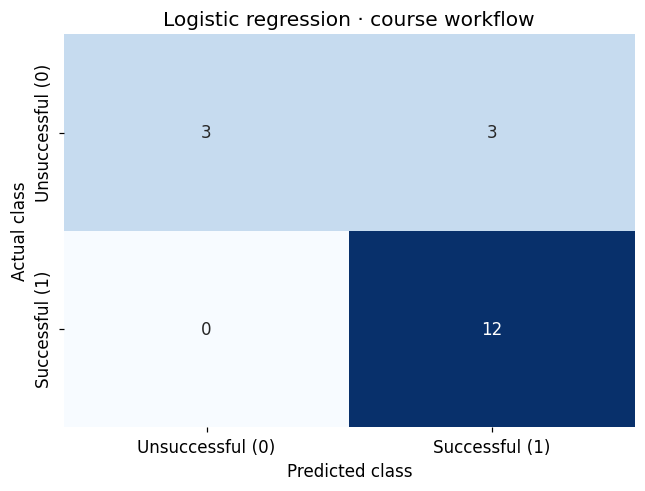

In [16]:
yhat = logreg_cv.predict(X_test)
logreg_cm = plot_confusion_matrix(
    Y_test, yhat, "Logistic regression · course workflow", "01_logistic_confusion.png"
)

The matrix reports actual counts from this run: upper-left is true negatives,
upper-right false positives, lower-left false negatives, and lower-right true
positives. A false positive predicts class 1 for an actual class 0 launch.
Counts are generated below rather than assumed from the template.

## TASK  6


Create a support vector machine object then  create a  <code>GridSearchCV</code> object  <code>svm_cv</code> with cv = 10.  Fit the object to find the best parameters from the dictionary <code>parameters</code>.


In [17]:
# Task 6: remove the repeated rbf entry without changing the unique candidates.
parameters = {
    "kernel": ["linear", "rbf", "poly", "sigmoid"],
    "C": np.logspace(-3, 3, 5),
    "gamma": np.logspace(-3, 3, 5),
}
svm = SVC()

In [18]:
parameter_grids["SVM"] = parameters.copy()
svm_cv = GridSearchCV(svm, parameters, cv=10, scoring="accuracy",
                     n_jobs=1, error_score="raise")
svm_cv.fit(X_train, Y_train)

GridSearchCV(cv=10, error_score='raise', estimator=SVC(), n_jobs=1,
             param_grid={'C': array([1.00000000e-03, 3.16227766e-02, 1.00000000e+00, 3.16227766e+01,
       1.00000000e+03]),
                         'gamma': array([1.00000000e-03, 3.16227766e-02, 1.00000000e+00, 3.16227766e+01,
       1.00000000e+03]),
                         'kernel': ['linear', 'rbf', 'poly', 'sigmoid']},
             scoring='accuracy')

In [19]:
print("tuned hpyerparameters :(best parameters) ",svm_cv.best_params_)
print("accuracy :",svm_cv.best_score_)

tuned hpyerparameters :(best parameters)  {'C': 1.0, 'gamma': 0.03162277660168379, 'kernel': 'sigmoid'}
accuracy : 0.8482142857142858


## TASK  7


Calculate the accuracy on the test data using the method <code>score</code>:


In [20]:
# Task 7
svm_accuracy = svm_cv.score(X_test, Y_test)
print(f"SVM test accuracy: {svm_accuracy:.2%}")

SVM test accuracy: 83.33%


We can plot the confusion matrix


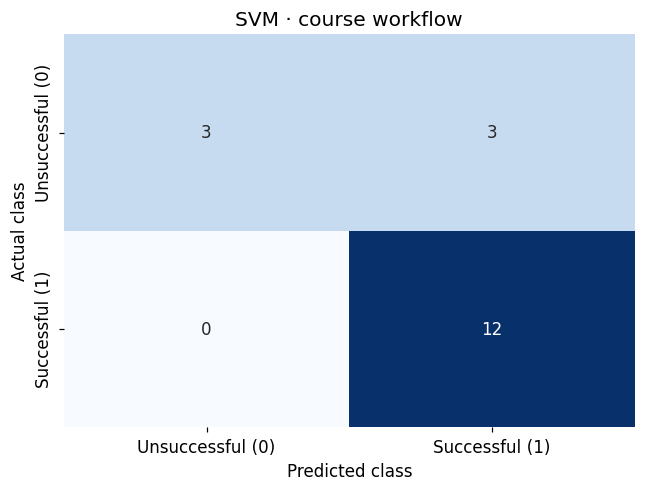

In [21]:
yhat = svm_cv.predict(X_test)
svm_cm = plot_confusion_matrix(
    Y_test, yhat, "SVM · course workflow", "02_svm_confusion.png"
)

## TASK  8


Create a decision tree classifier object then  create a  <code>GridSearchCV</code> object  <code>tree_cv</code> with cv = 10.  Fit the object to find the best parameters from the dictionary <code>parameters</code>.


In [22]:
# Task 8: old max_features='auto' meant 'sqrt' for classifiers.
# Keep its supported equivalent once, rather than searching duplicate values.
parameters = {
    "criterion": ["gini", "entropy"],
    "splitter": ["best", "random"],
    "max_depth": [2 * n for n in range(1, 10)],
    "max_features": ["sqrt"],
    "min_samples_leaf": [1, 2, 4],
    "min_samples_split": [2, 5, 10],
}
tree = DecisionTreeClassifier(random_state=2)

In [23]:
parameter_grids["Decision tree"] = parameters.copy()
tree_cv = GridSearchCV(tree, parameters, cv=10, scoring="accuracy",
                      n_jobs=1, error_score="raise")
tree_cv.fit(X_train, Y_train)

GridSearchCV(cv=10, error_score='raise',
             estimator=DecisionTreeClassifier(random_state=2), n_jobs=1,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [2, 4, 6, 8, 10, 12, 14, 16, 18],
                         'max_features': ['sqrt'],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'splitter': ['best', 'random']},
             scoring='accuracy')

In [24]:
print("tuned hpyerparameters :(best parameters) ",tree_cv.best_params_)
print("accuracy :",tree_cv.best_score_)

tuned hpyerparameters :(best parameters)  {'criterion': 'gini', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'splitter': 'random'}
accuracy : 0.8339285714285714


## TASK  9


Calculate the accuracy of tree_cv on the test data using the method <code>score</code>:


In [25]:
# Task 9
tree_accuracy = tree_cv.score(X_test, Y_test)
print(f"Decision tree test accuracy: {tree_accuracy:.2%}")

Decision tree test accuracy: 72.22%


We can plot the confusion matrix


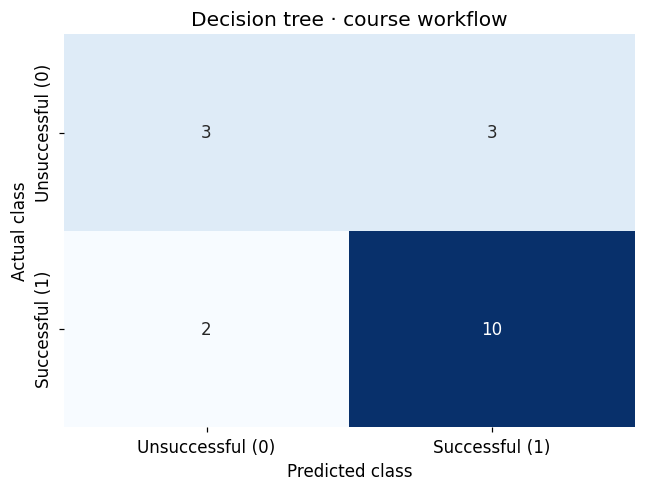

In [26]:
yhat = tree_cv.predict(X_test)
tree_cm = plot_confusion_matrix(
    Y_test, yhat, "Decision tree · course workflow", "03_tree_confusion.png"
)

## TASK  10


Create a k nearest neighbors object then  create a  <code>GridSearchCV</code> object  <code>knn_cv</code> with cv = 10.  Fit the object to find the best parameters from the dictionary <code>parameters</code>.


In [27]:
parameters = {'n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
              'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],
              'p': [1,2]}

KNN = KNeighborsClassifier()

In [28]:
# Task 10
parameter_grids["KNN"] = parameters.copy()
knn_cv = GridSearchCV(KNN, parameters, cv=10, scoring="accuracy",
                     n_jobs=1, error_score="raise")
knn_cv.fit(X_train, Y_train)

GridSearchCV(cv=10, error_score='raise', estimator=KNeighborsClassifier(),
             n_jobs=1,
             param_grid={'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],
                         'n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
                         'p': [1, 2]},
             scoring='accuracy')

In [29]:
print("tuned hpyerparameters :(best parameters) ",knn_cv.best_params_)
print("accuracy :",knn_cv.best_score_)

tuned hpyerparameters :(best parameters)  {'algorithm': 'auto', 'n_neighbors': 6, 'p': 1}
accuracy : 0.8339285714285714


## TASK  11


Calculate the accuracy of knn_cv on the test data using the method <code>score</code>:


In [30]:
# Task 11
knn_accuracy = knn_cv.score(X_test, Y_test)
print(f"KNN test accuracy: {knn_accuracy:.2%}")

KNN test accuracy: 83.33%


We can plot the confusion matrix


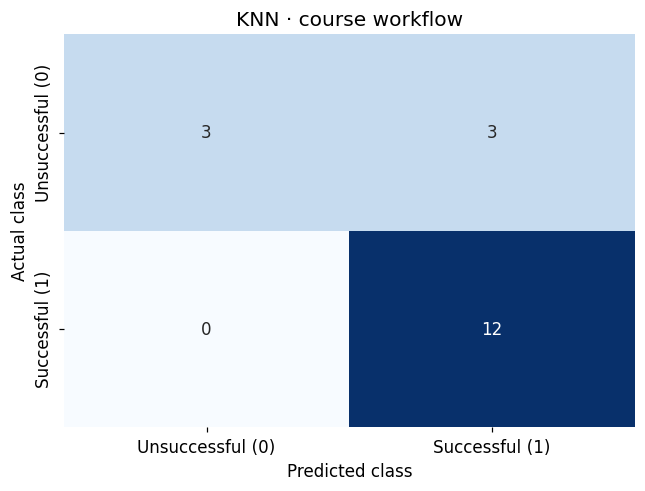

In [31]:
yhat = knn_cv.predict(X_test)
knn_cm = plot_confusion_matrix(
    Y_test, yhat, "KNN · course workflow", "04_knn_confusion.png"
)

## TASK  12


Compare test accuracy for all four methods, reporting all ties. Also compare
training cross-validation scores. Selecting a method because it wins on this
test set makes that set part of model selection; it is no longer an untouched
final evaluation. With only 18 test launches, one error changes accuracy by
5.56 percentage points.

,Model,CVAccuracy,CVStd,TestAccuracy,TN,FP,FN,TP,BestParameters
0,Logistic regression,0.821429,0.101330,0.833333,3,3,0,12,"{""C"": 1, ""penalty"": ""l2"", ""solver"": ""lbfgs""}"
1,SVM,0.848214,0.124553,0.833333,3,3,0,12,"{""C"": 1.0, ""gamma"": 0.03162277660168379, ""kern..."
2,Decision tree,0.833929,0.114076,0.722222,3,3,2,10,"{""criterion"": ""gini"", ""max_depth"": 10, ""max_fe..."
3,KNN,0.833929,0.114076,0.833333,3,3,0,12,"{""algorithm"": ""auto"", ""n_neighbors"": 6, ""p"": 1}"


Highest course test accuracy: 83.33%; method(s): Logistic regression, SVM, KNN
Highest mean training CV accuracy: SVM
Logistic regression: TN=3, FP=3, FN=0, TP=12


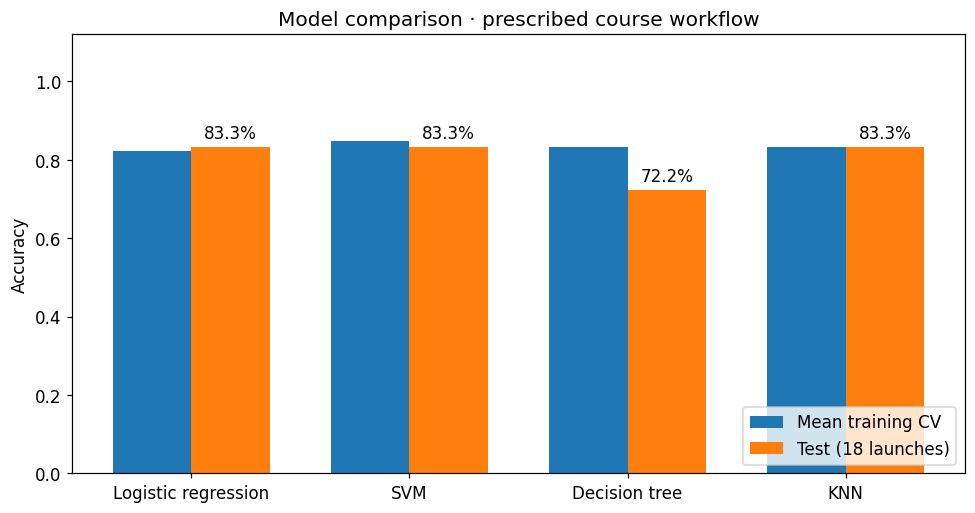

In [32]:
# Task 12
searches = {
    "Logistic regression": logreg_cv, "SVM": svm_cv,
    "Decision tree": tree_cv, "KNN": knn_cv,
}

def summarize_searches(fitted_searches, test_features, workflow):
    rows = []
    predictions = pd.DataFrame({
        "FlightNumber": data.iloc[test_indices]["FlightNumber"].to_numpy(),
        "ActualClass": Y_test,
    })
    for name, search in fitted_searches.items():
        prediction = search.predict(test_features)
        predictions[name] = prediction
        tn, fp, fn, tp = confusion_matrix(Y_test, prediction, labels=[0, 1]).ravel()
        rows.append({
            "Model": name, "CVAccuracy": search.best_score_,
            "CVStd": search.cv_results_["std_test_score"][search.best_index_],
            "TestAccuracy": search.score(test_features, Y_test),
            "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
            "BestParameters": json.dumps(search.best_params_),
        })
    results = pd.DataFrame(rows)
    results.to_csv(OUTPUT / f"{workflow}_model_comparison.csv", index=False)
    predictions.to_csv(OUTPUT / f"{workflow}_test_predictions.csv", index=False)
    return results, predictions

results, test_predictions = summarize_searches(searches, X_test, "course")
display(results)
best_test = results["TestAccuracy"].max()
best_methods = results.loc[np.isclose(results["TestAccuracy"], best_test), "Model"].tolist()
print(f"Highest course test accuracy: {best_test:.2%}; method(s): {', '.join(best_methods)}")
best_cv_model = results.loc[results["CVAccuracy"].idxmax(), "Model"]
print("Highest mean training CV accuracy:", best_cv_model)
tn, fp, fn, tp = logreg_cm.ravel()
print(f"Logistic regression: TN={tn}, FP={fp}, FN={fn}, TP={tp}")

fig, ax = plt.subplots(figsize=(9, 4.8))
positions = np.arange(len(results))
ax.bar(positions - 0.18, results["CVAccuracy"], 0.36, label="Mean training CV")
bars = ax.bar(positions + 0.18, results["TestAccuracy"], 0.36, label="Test (18 launches)")
ax.bar_label(bars, labels=[f"{value:.1%}" for value in results["TestAccuracy"]], padding=3)
ax.set(xticks=positions, xticklabels=results["Model"], ylim=(0, 1.12),
       ylabel="Accuracy", title="Model comparison · prescribed course workflow")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(OUTPUT / "05_model_comparison.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

## Additional check: fit scaling within each training fold

The required tasks above are complete. This comparison repeats the same grids
and 72/18 row split, but puts `StandardScaler` inside a `Pipeline`. Each CV
training fold fits its own scaler; the test rows never fit this scaler.
Choose the model family by **training CV accuracy**, then report its test score.

This addresses scaling leakage only. Earlier labs imputed payload masses and
generated feature categories before splitting. Reuse metadata and booster IDs
also warrant a point-in-time audit for deployment. A production evaluation
would rebuild preprocessing from raw training rows and use a future-time
holdout; these small historical experiments do not measure future performance.

Compatibility change: the old classifier setting `max_features="auto"` meant
`"sqrt"`. The grid now searches that supported option once. See the
[original parameter definition](https://scikit-learn.org/1.0/modules/generated/sklearn.tree.DecisionTreeClassifier.html)
and [current supported settings](https://scikit-learn.org/1.6/modules/generated/sklearn.tree.DecisionTreeClassifier.html).

In [33]:
raw_train = X_raw.iloc[train_indices]
raw_test = X_raw.iloc[test_indices]
fold_searches = {}
for name, course_search in searches.items():
    pipeline = Pipeline([
        ("scale", preprocessing.StandardScaler()),
        ("model", clone(course_search.estimator)),
    ])
    grid = {f"model__{key}": values for key, values in parameter_grids[name].items()}
    search = GridSearchCV(pipeline, grid, cv=10, scoring="accuracy",
                          n_jobs=1, error_score="raise")
    search.fit(raw_train, Y_train)
    fold_searches[name] = search
    # The refitted scaler has seen only the 72 outer-training rows.
    scaler = search.best_estimator_.named_steps["scale"]
    assert scaler.n_samples_seen_ == len(train_indices)
    np.testing.assert_allclose(scaler.mean_, raw_train.mean().to_numpy())
    print(f"{name}: fold-fitted scaling CV accuracy = {search.best_score_:.2%}")

# Choose using training CV only, before examining this comparison's test scores.
selected_model = max(fold_searches, key=lambda name: fold_searches[name].best_score_)
fold_results, fold_predictions = summarize_searches(
    fold_searches, raw_test, "fold_scaled"
)
display(fold_results)
selected_score = fold_searches[selected_model].score(raw_test, Y_test)
print(f"CV-selected model: {selected_model}; test accuracy: {selected_score:.2%}")
majority_class = int(np.argmax(np.bincount(Y_train)))
baseline = accuracy_score(Y_test, np.full(Y_test.shape, majority_class))
print(f"Training-majority baseline test accuracy: {baseline:.2%}")

manifest = {
    "sklearn_version": sklearn.__version__,
    "feature_columns": X_raw.columns.tolist(),
    "train_indices": train_indices.tolist(),
    "test_indices": test_indices.tolist(),
    "course_test_winners": best_methods,
    "fold_scaled_cv_selected_model": selected_model,
    "fold_scaled_selected_test_accuracy": selected_score,
    "majority_baseline_test_accuracy": baseline,
    "scaler_training_rows": {
        name: int(search.best_estimator_.named_steps["scale"].n_samples_seen_)
        for name, search in fold_searches.items()
    },
}
(OUTPUT / "run_summary.json").write_text(json.dumps(manifest, indent=2) + "\n")
display(Markdown(
    f"**Conclusion.** In the prescribed course workflow, {', '.join(best_methods)} "
    f"achieve the highest observed test accuracy ({best_test:.2%}). "
    f"With scaling fitted inside the training folds, training CV selects "
    f"**{selected_model}**, which scores **{selected_score:.2%}** on the same "
    f"18 test launches. The majority baseline is {baseline:.2%}. "
    "These results describe this split and dataset; they do not establish a "
    "universally best model or an unbiased estimate of future launch performance."
))

Logistic regression: fold-fitted scaling CV accuracy = 80.71%


SVM: fold-fitted scaling CV accuracy = 83.57%


Decision tree: fold-fitted scaling CV accuracy = 83.39%


KNN: fold-fitted scaling CV accuracy = 81.96%


,Model,CVAccuracy,CVStd,TestAccuracy,TN,FP,FN,TP,BestParameters
0,Logistic regression,0.807143,0.105281,0.833333,3,3,0,12,"{""model__C"": 1, ""model__penalty"": ""l2"", ""model..."
1,SVM,0.835714,0.114564,0.833333,3,3,0,12,"{""model__C"": 1.0, ""model__gamma"": 0.0316227766..."
2,Decision tree,0.833929,0.114076,0.722222,3,3,2,10,"{""model__criterion"": ""gini"", ""model__max_depth..."
3,KNN,0.819643,0.119109,0.833333,3,3,0,12,"{""model__algorithm"": ""auto"", ""model__n_neighbo..."


CV-selected model: SVM; test accuracy: 83.33%
Training-majority baseline test accuracy: 66.67%


**Conclusion.** In the prescribed course workflow, Logistic regression, SVM, KNN achieve the highest observed test accuracy (83.33%). With scaling fitted inside the training folds, training CV selects **SVM**, which scores **83.33%** on the same 18 test launches. The majority baseline is 66.67%. These results describe this split and dataset; they do not establish a universally best model or an unbiased estimate of future launch performance.

## Authors


[Pratiksha Verma](https://www.linkedin.com/in/pratiksha-verma-6487561b1/)


<!--## Change Log--!>


<!--| Date (YYYY-MM-DD) | Version | Changed By      | Change Description      |
| ----------------- | ------- | -------------   | ----------------------- |
| 2022-11-09        | 1.0     | Pratiksha Verma | Converted initial version to Jupyterlite|--!>


### <h3 align="center"> IBM Corporation 2022. All rights reserved. <h3/>
